# My Content : choisir le système de recommandation d'articles

Ce notebook répond à la fonctionnalité prioritaire du MVP (la première version minimale de l'application) :
"En tant qu'utilisateur de l'application, je vais recevoir une sélection de cinq articles."

On y compare plusieurs façons de choisir ces 5 articles, on garde la meilleure, puis on prépare le fichier
que l'Azure Function lira pour faire ses recommandations.

Plan :
1. Chargement et exploration des données
2. Protocole d'évaluation : comment on mesure qu'une recommandation est bonne
3. Quatre approches : popularité, contenu, filtrage collaboratif, mélange popularité et contenu
4. Choix sur le jeu de validation, puis vérification unique sur le jeu de test
5. Réduction des embeddings par ACP et export du modèle pour Azure

## 1. Chargement et exploration

Les données viennent du portail d'actualités brésilien Globo.com (jeu public Kaggle). Il y a trois sources :
- les clics : qui a cliqué sur quel article, et quand (un fichier CSV par heure) ;
- les métadonnées des articles : catégorie, date de publication, nombre de mots ;
- les embeddings des articles. Un embedding est une liste de 250 nombres qui résume le contenu d'un article.
  Deux articles qui parlent du même sujet ont des embeddings proches. Ils ont été calculés par Globo.com avec un
  réseau de neurones, on les utilise tels quels.

In [1]:
import glob
import os
import pickle

import implicit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import binomtest
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

# Graine aléatoire fixée partout pour que chaque exécution donne exactement les mêmes chiffres
GRAINE = 42
DOSSIER_DONNEES = "../data"

# Les dates des clics sont en millisecondes : une heure = 3 600 000 ms
HEURE_MS = 3600 * 1000

In [2]:
# On ne garde que les trois colonnes utiles des clics : qui, quel article, quand.
# Les autres (pays, appareil, système...) ne servent pas aux approches testées ici.
# Piège rencontré : le fichier clicks_hour_100.csv est vide. Pandas donne alors à ses colonnes le type
# "objet" (texte) au lieu d'entier, et une fois tous les fichiers assemblés, toute la colonne passe en
# "objet". Les identifiants d'articles ne peuvent plus servir d'indices dans le tableau des embeddings.
# On impose donc le type entier dès la lecture.
fichiers = sorted(glob.glob(f"{DOSSIER_DONNEES}/clicks/*.csv"))
clics = pd.concat(
    [pd.read_csv(f, usecols=["user_id", "click_article_id", "click_timestamp"], dtype="int64") for f in fichiers],
    ignore_index=True,
).sort_values("click_timestamp", ignore_index=True)

articles = pd.read_csv(f"{DOSSIER_DONNEES}/articles_metadata.csv")

with open(f"{DOSSIER_DONNEES}/articles_embeddings.pickle", "rb") as f:
    embeddings = pickle.load(f)

print(f"{len(fichiers)} fichiers de clics, {len(clics):,} clics")
print(f"{clics.user_id.nunique():,} utilisateurs, {clics.click_article_id.nunique():,} articles cliqués")
print(f"{len(articles):,} articles dans le catalogue, embeddings de taille {embeddings.shape}")

385 fichiers de clics, 2,988,181 clics
322,897 utilisateurs, 46,033 articles cliqués
364,047 articles dans le catalogue, embeddings de taille (364047, 250)


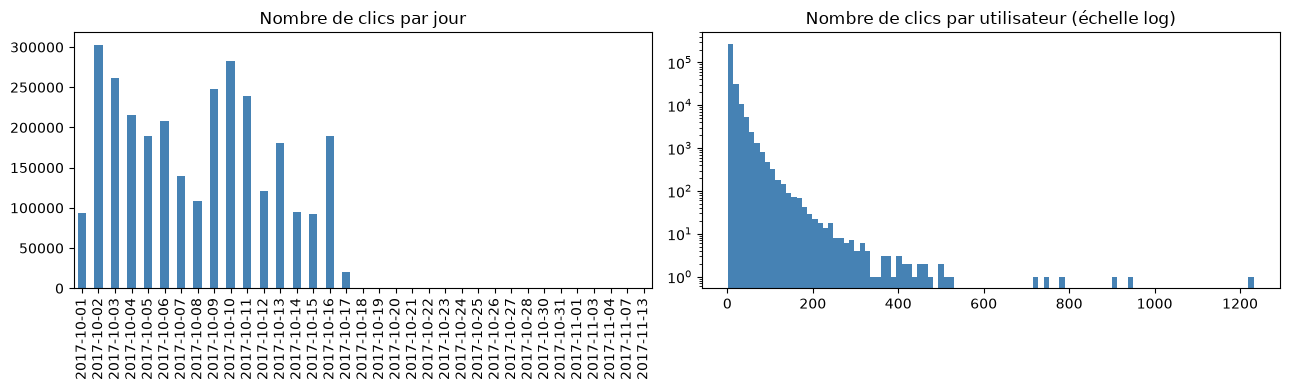

Clics par utilisateur :
count    322897.0
mean          9.3
std          14.9
min           2.0
25%           2.0
50%           4.0
75%          10.0
max        1232.0

Clics après le 17/10/2017 : 712


In [3]:
# Combien de clics par jour ? Cela fixe les dates qu'on peut utiliser pour évaluer.
jours = pd.to_datetime(clics.click_timestamp, unit="ms").dt.date
clics_par_jour = jours.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
clics_par_jour.plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Nombre de clics par jour")
axes[0].set_xlabel("")

# Combien de clics par utilisateur ? Échelle logarithmique car quelques gros lecteurs écrasent le reste.
clics_par_user = clics.groupby("user_id").size()
axes[1].hist(clics_par_user, bins=100, color="steelblue")
axes[1].set_yscale("log")
axes[1].set_title("Nombre de clics par utilisateur (échelle log)")
plt.tight_layout()
plt.show()

print("Clics par utilisateur :")
print(clics_par_user.describe().round(1).to_string())
print(f"\nClics après le 17/10/2017 : {(jours > pd.Timestamp('2017-10-17').date()).sum()}")

In [4]:
# Quel âge ont les articles au moment où on clique dessus ?
# Si on lit surtout des articles de quelques heures, la fraîcheur comptera beaucoup dans la recommandation.
age = clics.merge(articles[["article_id", "created_at_ts"]], left_on="click_article_id", right_on="article_id")
age_heures = (age.click_timestamp - age.created_at_ts) / HEURE_MS
print(f"Âge médian d'un article au moment du clic : {age_heures.median():.1f} heures")
print(f"Part des clics sur un article de moins de 24 heures : {(age_heures < 24).mean():.1%}")

Âge médian d'un article au moment du clic : 8.0 heures
Part des clics sur un article de moins de 24 heures : 87.7%


Ce qu'on retient de l'exploration :
- presque tous les clics ont lieu entre le 1er et le 17 octobre 2017, il n'en reste que quelques centaines après ;
- chaque utilisateur a au moins 2 clics, mais la moitié en a très peu ;
- on lit surtout des articles récents (voir l'âge médian ci-dessus). C'est de l'actualité : un article d'hier
  intéresse déjà beaucoup moins.

## 2. Protocole d'évaluation

### La métrique métier : le taux de réussite à 5 (HR@5)

La promesse faite à l'utilisateur est une sélection de 5 articles. On considère que la sélection est réussie
si l'utilisateur lit ensuite au moins un de ces 5 articles. Le HR@5 (pour "hit rate at 5", taux de réussite
à 5) est la part des utilisateurs pour lesquels c'est le cas. C'est simple à expliquer à Samia : "sur 100
lecteurs, combien trouvent au moins un article qui les intéresse dans nos 5 propositions".

On ne compte que les articles que l'utilisateur n'avait pas encore lus : recommander un article déjà lu
n'apporte rien.

### Le découpage dans le temps

Pour être honnête, on se met dans les conditions réelles : le système ne connaît que le passé et doit deviner
ce qui sera lu ensuite. On coupe donc les clics à une date :
- tout ce qui est avant la date sert à construire les recommandations ;
- ce qui est après sert à vérifier si elles étaient bonnes.

On fait deux découpages :
- validation : on connaît les clics jusqu'au 10 octobre inclus, on devine ceux du 11 et du 12. C'est ici
  qu'on compare les approches et qu'on choisit les réglages ;
- test : on connaît les clics jusqu'au 12 octobre inclus, on devine ceux à partir du 13. Ce jeu ne sert
  qu'une seule fois, à la fin, pour confirmer le choix sans l'avoir influencé.

On évalue les utilisateurs qui ont un historique avant la date et qui lisent au moins un nouvel article après.

In [5]:
def decouper(clics, debut_cible, fin_cible=None):
    """Coupe les clics à la date debut_cible.

    Renvoie :
    - connus : les clics d'avant, les seuls que le système a le droit de voir ;
    - deja_lus : pour chaque utilisateur, l'ensemble des articles qu'il a déjà lus ;
    - a_lire : pour chaque utilisateur évalué, les articles NOUVEAUX qu'il a lus après la date ;
    - utilisateurs : la liste des utilisateurs évalués.
    """
    debut = pd.Timestamp(debut_cible).value // 10**6  # date convertie en millisecondes
    connus = clics[clics.click_timestamp < debut]
    cible = clics[clics.click_timestamp >= debut]
    if fin_cible is not None:
        cible = cible[cible.click_timestamp < pd.Timestamp(fin_cible).value // 10**6]

    deja_lus = connus.groupby("user_id").click_article_id.agg(set)
    lus_apres = cible.groupby("user_id").click_article_id.agg(set)

    # On garde les utilisateurs présents des deux côtés, et on retire de leur cible ce qu'ils avaient déjà lu
    a_lire = {}
    for u in lus_apres.index.intersection(deja_lus.index):
        nouveaux = lus_apres[u] - deja_lus[u]
        if nouveaux:
            a_lire[u] = nouveaux
    utilisateurs = np.array(sorted(a_lire))
    return connus, deja_lus, a_lire, utilisateurs


VALIDATION = decouper(clics, "2017-10-11", "2017-10-13")
TEST = decouper(clics, "2017-10-13")
print(f"Validation : {len(VALIDATION[0]):,} clics connus, {len(VALIDATION[3]):,} utilisateurs évalués")
print(f"Test       : {len(TEST[0]):,} clics connus, {len(TEST[3]):,} utilisateurs évalués")

Validation : 2,049,488 clics connus, 72,683 utilisateurs évalués
Test       : 2,409,924 clics connus, 97,505 utilisateurs évalués


In [6]:
def reussites(recos, a_lire, utilisateurs):
    """Pour chaque utilisateur : 1 si au moins un des 5 articles recommandés a été lu ensuite, 0 sinon."""
    return np.array([len(set(recos[u]) & a_lire[u]) > 0 for u in utilisateurs])


resultats = []  # on y range chaque mesure pour le tableau récapitulatif


def noter(nom, reglage, jeu, succes):
    """Calcule le HR@5 et sa marge d'erreur, puis l'ajoute au tableau des résultats.

    La marge d'erreur (intervalle de confiance à 95 %) dit de combien le chiffre pourrait bouger si on
    refaisait la mesure sur d'autres utilisateurs. Deux approches dont les marges se chevauchent largement
    ne sont pas vraiment départagées.
    """
    hr = succes.mean()
    marge = 1.96 * np.sqrt(hr * (1 - hr) / len(succes))
    resultats.append({"approche": nom, "réglage": reglage, "jeu": jeu, "HR@5": hr, "marge 95 %": marge})
    print(f"{nom:<12} {reglage:<26} {jeu:<10} HR@5 = {hr:.2%} (+/- {marge:.2%})")
    return succes

## 3. Les approches comparées

### 3.1 Popularité récente (approche de référence)

L'idée la plus simple : proposer à tout le monde les articles les plus cliqués des dernières heures, en
retirant ceux que l'utilisateur a déjà lus. Elle ne personnalise rien, mais elle sert de point de comparaison :
une approche plus compliquée doit faire mieux qu'elle pour mériter sa place.

Le seul réglage est la durée de la fenêtre : les dernières 1, 2, 3, 6 ou 24 heures.

In [7]:
def classement_popularite(connus, heures):
    """Articles classés par nombre de clics sur les dernières `heures` heures connues."""
    fin = connus.click_timestamp.max()
    recents = connus[connus.click_timestamp > fin - heures * HEURE_MS]
    return recents.click_article_id.value_counts()


def recommander_popularite(connus, deja_lus, utilisateurs, heures, k=5):
    # 200 candidats suffisent largement : même un gros lecteur n'en a pas déjà lu 195 parmi les plus populaires
    top = classement_popularite(connus, heures).index[:200]
    return {u: [a for a in top if a not in deja_lus[u]][:k] for u in utilisateurs}


connus, deja_lus, a_lire, utilisateurs = VALIDATION
for heures in [1, 2, 3, 6, 24]:
    recos = recommander_popularite(connus, deja_lus, utilisateurs, heures)
    noter("popularité", f"{heures} h", "validation", reussites(recos, a_lire, utilisateurs))

popularité   1 h                        validation HR@5 = 30.14% (+/- 0.33%)


popularité   2 h                        validation HR@5 = 28.06% (+/- 0.33%)


popularité   3 h                        validation HR@5 = 27.49% (+/- 0.32%)


popularité   6 h                        validation HR@5 = 14.07% (+/- 0.25%)


popularité   24 h                       validation HR@5 = 8.19% (+/- 0.20%)


### 3.2 Filtrage par le contenu (embeddings)

Ici on personnalise : on recommande des articles qui ressemblent à ceux que l'utilisateur a déjà lus.
- Le profil de l'utilisateur est la moyenne des embeddings des articles qu'il a lus.
- On mesure la ressemblance entre ce profil et chaque article avec la similarité cosinus : elle vaut 1 si les
  deux vecteurs pointent dans la même direction (même sujet) et environ 0 s'ils n'ont rien à voir. C'est la
  mesure habituelle pour comparer des embeddings, car elle ne dépend pas de leur longueur.
- Pour ne pas proposer des articles de 2014, on limite les candidats aux articles cliqués dans les dernières
  heures connues (6 h ou 24 h, à régler).

Avantages : chaque utilisateur a sa sélection, et un nouvel article est recommandable dès qu'on a son embedding.
Inconvénient : on enferme le lecteur dans ce qu'il connaît déjà, et on ignore ce qui fait l'actualité du moment.

In [8]:
# On divise chaque embedding par sa longueur : le produit de deux vecteurs ainsi normalisés
# est directement leur similarité cosinus, ce qui évite de recalculer les longueurs à chaque fois.
EMB = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)


def profils(connus, utilisateurs, emb):
    """Profil de chaque utilisateur = moyenne des embeddings des articles qu'il a lus, renormalisée."""
    historiques = connus[connus.user_id.isin(utilisateurs)].groupby("user_id").click_article_id.agg(list)
    P = np.stack([emb[historiques[u]].mean(axis=0) for u in utilisateurs])
    return P / np.linalg.norm(P, axis=1, keepdims=True)


def meilleurs_indices(scores, n):
    """Indices des n plus grands scores de chaque ligne, du plus grand au plus petit.

    argpartition isole les n meilleurs sans trier toute la ligne (bien plus rapide sur des milliers de
    candidats), puis on ne trie que ces n-là.
    """
    n = min(n, scores.shape[1])
    idx = np.argpartition(-scores, n - 1, axis=1)[:, :n]
    ordre = np.argsort(-np.take_along_axis(scores, idx, axis=1), axis=1)
    return np.take_along_axis(idx, ordre, axis=1)


def recommander_contenu(connus, deja_lus, utilisateurs, heures, k=5, emb=EMB):
    fin = connus.click_timestamp.max()
    candidats = connus[connus.click_timestamp > fin - heures * HEURE_MS].click_article_id.unique()
    P = profils(connus, utilisateurs, emb)
    recos = {}
    # On traite les utilisateurs par paquets de 5 000 pour ne pas créer une matrice de scores
    # de plusieurs Go en mémoire (utilisateurs x candidats).
    for debut in range(0, len(utilisateurs), 5000):
        scores = P[debut:debut + 5000] @ emb[candidats].T
        top = meilleurs_indices(scores, 50)
        for i, u in enumerate(utilisateurs[debut:debut + 5000]):
            recos[u] = [a for a in candidats[top[i]] if a not in deja_lus[u]][:k]
    return recos


for heures in [6, 24]:
    recos = recommander_contenu(connus, deja_lus, utilisateurs, heures)
    noter("contenu", f"candidats {heures} h", "validation", reussites(recos, a_lire, utilisateurs))

contenu      candidats 6 h              validation HR@5 = 3.09% (+/- 0.13%)


contenu      candidats 24 h             validation HR@5 = 1.90% (+/- 0.10%)


### 3.3 Filtrage collaboratif (ALS)

Autre façon de personnaliser : "les lecteurs qui ont lu les mêmes articles que vous ont aussi lu ceux-ci".
On n'utilise pas le contenu des articles, seulement qui a lu quoi.

On range les clics dans un grand tableau utilisateurs x articles, puis l'algorithme ALS (Alternating Least
Squares, moindres carrés alternés) résume chaque utilisateur et chaque article par quelques nombres appelés
facteurs. Un article est recommandé si ses facteurs ressemblent à ceux de l'utilisateur. On utilise la
bibliothèque `implicit`, faite pour les données "implicites" comme des clics (on sait ce que la personne a lu,
mais pas si elle a aimé). Le réglage testé est le nombre de facteurs : 32, 64 ou 128.

Avantages : découvre des liens que le contenu ne voit pas. Inconvénients : un nouvel utilisateur ou un nouvel
article n'a pas de facteurs tant qu'on n'a pas réentraîné le modèle, ce qui est gênant pour de l'actualité.

In [9]:
def recommander_als(connus, deja_lus, utilisateurs, facteurs, k=5):
    # Chaque utilisateur et chaque article reçoit un numéro de ligne / colonne dans le tableau
    ids_users = connus.user_id.unique()
    ids_articles = connus.click_article_id.unique()
    ligne = pd.Series(np.arange(len(ids_users)), index=ids_users)
    colonne = pd.Series(np.arange(len(ids_articles)), index=ids_articles)

    # Case (utilisateur, article) = nombre de clics. Le tableau est "creux" (sparse) : on ne stocke
    # que les cases non vides, sinon il ferait des centaines de milliers x des dizaines de milliers de cases.
    comptes = connus.groupby(["user_id", "click_article_id"]).size()
    M = sp.csr_matrix(
        (
            comptes.values.astype(np.float32),
            (ligne[comptes.index.get_level_values(0)].values, colonne[comptes.index.get_level_values(1)].values),
        ),
        shape=(len(ids_users), len(ids_articles)),
    )

    # implicit gère lui-même ses calculs en parallèle : on coupe le parallélisme de la bibliothèque de
    # calcul matriciel (BLAS) pendant la création et l'entraînement du modèle, comme le recommande implicit,
    # sinon les deux se gênent et l'entraînement devient très lent. La création est dans le bloc aussi,
    # car c'est à ce moment qu'implicit vérifie le réglage (et affiche un avertissement s'il est mauvais).
    with threadpool_limits(1, "blas"):
        modele = implicit.cpu.als.AlternatingLeastSquares(
            factors=facteurs, regularization=0.05, iterations=15, random_state=GRAINE
        )
        modele.fit(M, show_progress=False)

    lignes = ligne[utilisateurs].values
    ids, _ = modele.recommend(lignes, M[lignes], N=k, filter_already_liked_items=True)
    return {u: list(ids_articles[ids[i]]) for i, u in enumerate(utilisateurs)}


for facteurs in [32, 64, 128]:
    recos = recommander_als(connus, deja_lus, utilisateurs, facteurs)
    noter("ALS", f"{facteurs} facteurs", "validation", reussites(recos, a_lire, utilisateurs))

ALS          32 facteurs                validation HR@5 = 0.60% (+/- 0.06%)


ALS          64 facteurs                validation HR@5 = 0.58% (+/- 0.06%)


ALS          128 facteurs               validation HR@5 = 0.82% (+/- 0.07%)


### 3.4 Mélange popularité et contenu

Les résultats précédents montrent que l'actualité du moment pèse beaucoup. On essaie donc de combiner les deux :
- on part des 300 articles les plus populaires de la meilleure fenêtre trouvée en 3.1 ;
- on leur donne un score qui mélange leur popularité et leur ressemblance avec le profil de l'utilisateur :

  score = alpha x popularité + (1 - alpha) x similarité

  La popularité est ramenée entre 0 et 1 (nombre de clics divisé par celui de l'article le plus cliqué), comme
  la similarité cosinus, pour que les deux soient comparables.
- alpha = 1 redonne la popularité pure, alpha = 0 le contenu pur sur ces 300 articles. On teste plusieurs
  valeurs entre les deux.

In [10]:
# Meilleure fenêtre de popularité trouvée sur la validation (et uniquement sur la validation)
tableau_val = pd.DataFrame(resultats)
meilleure_pop = tableau_val[tableau_val.approche == "popularité"].sort_values("HR@5").iloc[-1]
HEURES_POP = int(meilleure_pop["réglage"].split()[0])
print(f"Fenêtre de popularité retenue : {HEURES_POP} h")


def recommander_melange(connus, deja_lus, utilisateurs, heures, alpha, k=5, emb=EMB):
    pop = classement_popularite(connus, heures).iloc[:300]
    candidats = pop.index.values
    score_pop = pop.values / pop.values[0]          # popularité ramenée entre 0 et 1
    similarite = profils(connus, utilisateurs, emb) @ emb[candidats].T
    score = alpha * score_pop + (1 - alpha) * similarite
    top = meilleurs_indices(score, 50)
    return {u: [a for a in candidats[top[i]] if a not in deja_lus[u]][:k] for i, u in enumerate(utilisateurs)}


for alpha in [0.0, 0.5, 0.7, 0.8, 0.9, 1.0]:
    recos = recommander_melange(connus, deja_lus, utilisateurs, HEURES_POP, alpha)
    noter("mélange", f"{HEURES_POP} h, alpha {alpha}", "validation", reussites(recos, a_lire, utilisateurs))

Fenêtre de popularité retenue : 1 h


mélange      1 h, alpha 0.0             validation HR@5 = 5.20% (+/- 0.16%)


mélange      1 h, alpha 0.5             validation HR@5 = 30.11% (+/- 0.33%)


mélange      1 h, alpha 0.7             validation HR@5 = 30.33% (+/- 0.33%)


mélange      1 h, alpha 0.8             validation HR@5 = 30.31% (+/- 0.33%)


mélange      1 h, alpha 0.9             validation HR@5 = 30.24% (+/- 0.33%)


mélange      1 h, alpha 1.0             validation HR@5 = 30.14% (+/- 0.33%)


## 4. Choix sur la validation, puis test

On prend, pour chaque approche, le réglage qui a le meilleur HR@5 en validation.

Pour savoir si l'écart entre deux approches est réel ou dû au hasard, on utilise le test de McNemar. Il compare
les deux approches sur les mêmes utilisateurs, en ne regardant que ceux pour qui elles ne sont pas d'accord
(l'une réussit, l'autre échoue). Si l'une gagne nettement plus souvent que l'autre sur ces cas-là, la p-valeur
est petite. Sous 0,05, on considère l'écart comme réel.

In [11]:
tableau_val = pd.DataFrame(resultats)
meilleurs = tableau_val.loc[tableau_val.groupby("approche")["HR@5"].idxmax()].sort_values("HR@5", ascending=False)
print(meilleurs[["approche", "réglage", "HR@5", "marge 95 %"]].to_string(index=False, float_format="{:.2%}".format))

ALPHA = float(meilleurs.set_index("approche").loc["mélange", "réglage"].split("alpha ")[1])
FACTEURS = int(meilleurs.set_index("approche").loc["ALS", "réglage"].split()[0])
HEURES_CONTENU = int(meilleurs.set_index("approche").loc["contenu", "réglage"].split()[1])
print(f"\nRéglages retenus : popularité {HEURES_POP} h, contenu {HEURES_CONTENU} h, ALS {FACTEURS} facteurs, alpha {ALPHA}")

  approche        réglage   HR@5  marge 95 %
   mélange 1 h, alpha 0.7 30.33%       0.33%
popularité            1 h 30.14%       0.33%
   contenu  candidats 6 h  3.09%       0.13%
       ALS   128 facteurs  0.82%       0.07%

Réglages retenus : popularité 1 h, contenu 6 h, ALS 128 facteurs, alpha 0.7


In [12]:
def mcnemar(succes_a, succes_b):
    """Test de McNemar : l'écart entre deux approches mesurées sur les mêmes utilisateurs est-il réel ?"""
    a_seul = int((succes_a & ~succes_b).sum())   # utilisateurs où seule A réussit
    b_seul = int((~succes_a & succes_b).sum())   # utilisateurs où seule B réussit
    p = binomtest(a_seul, a_seul + b_seul, 0.5).pvalue
    return a_seul, b_seul, p


s_pop = reussites(recommander_popularite(connus, deja_lus, utilisateurs, HEURES_POP), a_lire, utilisateurs)
s_mel = reussites(recommander_melange(connus, deja_lus, utilisateurs, HEURES_POP, ALPHA), a_lire, utilisateurs)
a_seul, b_seul, p = mcnemar(s_mel, s_pop)
print(f"Validation, mélange contre popularité : mélange seul gagnant {a_seul}, popularité seule gagnante {b_seul}, p = {p:.3f}")

Validation, mélange contre popularité : mélange seul gagnant 367, popularité seule gagnante 227, p = 0.000


### Test final

On rejoue chaque approche avec son réglage retenu sur le jeu de test (clics connus jusqu'au 12 octobre, cible à
partir du 13). Rien n'est choisi ici : on vérifie seulement que le classement trouvé en validation tient sur des
jours que le choix n'a jamais vus.

In [13]:
connus, deja_lus, a_lire, utilisateurs = TEST
succes_test = {
    "popularité": noter("popularité", f"{HEURES_POP} h", "test",
                        reussites(recommander_popularite(connus, deja_lus, utilisateurs, HEURES_POP), a_lire, utilisateurs)),
    "contenu": noter("contenu", f"candidats {HEURES_CONTENU} h", "test",
                     reussites(recommander_contenu(connus, deja_lus, utilisateurs, HEURES_CONTENU), a_lire, utilisateurs)),
    "ALS": noter("ALS", f"{FACTEURS} facteurs", "test",
                 reussites(recommander_als(connus, deja_lus, utilisateurs, FACTEURS), a_lire, utilisateurs)),
    "mélange": noter("mélange", f"{HEURES_POP} h, alpha {ALPHA}", "test",
                     reussites(recommander_melange(connus, deja_lus, utilisateurs, HEURES_POP, ALPHA), a_lire, utilisateurs)),
}
a_seul, b_seul, p = mcnemar(succes_test["mélange"], succes_test["popularité"])
print(f"\nTest, mélange contre popularité : mélange seul gagnant {a_seul}, popularité seule gagnante {b_seul}, p = {p:.3f}")

popularité   1 h                        test       HR@5 = 17.79% (+/- 0.24%)


contenu      candidats 6 h              test       HR@5 = 1.09% (+/- 0.07%)


ALS          128 facteurs               test       HR@5 = 0.63% (+/- 0.05%)


mélange      1 h, alpha 0.7             test       HR@5 = 17.18% (+/- 0.24%)

Test, mélange contre popularité : mélange seul gagnant 1048, popularité seule gagnante 1649, p = 0.000


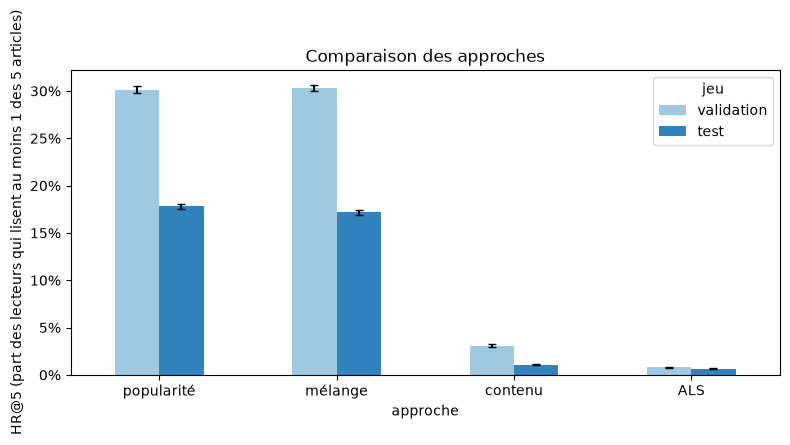

jeu          test  validation
approche                     
popularité 17.79%      30.14%
mélange    17.18%      30.33%
contenu     1.09%       3.09%
ALS         0.63%       0.82%


In [14]:
# Graphique récapitulatif : HR@5 de chaque approche, validation et test côte à côte, avec la marge d'erreur
tableau = pd.DataFrame(resultats)
retenus = pd.concat([
    tableau[(tableau.jeu == "test")],
    tableau[tableau.jeu == "validation"].merge(
        tableau[tableau.jeu == "test"][["approche", "réglage"]], on=["approche", "réglage"]),
])
pivot = retenus.pivot(index="approche", columns="jeu", values="HR@5").loc[["popularité", "mélange", "contenu", "ALS"]]
marges = retenus.pivot(index="approche", columns="jeu", values="marge 95 %").loc[pivot.index]

ax = pivot[["validation", "test"]].plot.bar(yerr=marges[["validation", "test"]], figsize=(8, 4), rot=0,
                                            color=["#9ecae1", "#3182bd"], capsize=3)
ax.set_ylabel("HR@5 (part des lecteurs qui lisent au moins 1 des 5 articles)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Comparaison des approches")
plt.tight_layout()
plt.show()
print(pivot.to_string(float_format="{:.2%}".format))

### Conclusion de la comparaison

Les chiffres ci-dessous viennent des cellules précédentes (tableau de la validation, cellule de test et
graphique récapitulatif).

- La popularité de la dernière heure est de très loin la meilleure base : environ 30 % de réussite en validation
  et 18 % en test. Le contenu seul et l'ALS restent sous 3,1 %. C'est cohérent avec l'exploration : on lit
  surtout des articles de quelques heures, et ces deux approches ne savent pas ce qui fait l'actualité du moment.
  L'ALS est en plus pénalisée par le fait qu'elle ne connaît que les articles déjà cliqués avant la date de coupure.
- En validation, le mélange avec alpha = 0,7 fait un peu mieux que la popularité seule (+0,19 point), et le test
  de McNemar dit que cet écart est réel.
- Sur le test, c'est l'inverse : la popularité seule fait mieux que le mélange (+0,6 point), écart lui aussi réel.
  Le petit gain de personnalisation trouvé sur le 11 et le 12 octobre ne se retrouve donc pas sur les jours
  suivants. Le HR@5 baisse aussi pour toutes les approches entre validation et test, car la période et les
  utilisateurs évalués ne sont pas les mêmes.

Décision : on déploie le mélange avec alpha = 0,7, puisque c'est le choix fait sur la validation, et on ne
change pas ce choix après avoir vu le test (sinon le test servirait à choisir et ne mesurerait plus rien
d'honnête). Il personnalise la sélection, comme le demande la mission, et un nouvel utilisateur sans historique
reçoit simplement les articles populaires.

Limite assumée : sur le test, ce mélange perd 0,6 point face à la popularité seule. C'est pour cela que alpha
est rangé dans le fichier du modèle et pas écrit dans le code de l'Azure Function : passer à alpha = 1
(popularité pure) ou à une autre valeur ne demande aucun redéploiement. En production, la bonne valeur se
choisirait avec un test A/B (deux groupes de lecteurs reçoivent chacun une version, on garde celle qui est la
plus lue), sur plusieurs semaines plutôt que sur deux jours.

## 5. Réduction des embeddings et export du modèle pour Azure

Le fichier d'embeddings fait 364 Mo. Julien conseille de le réduire avec une ACP (analyse en composantes
principales) : c'est une méthode qui remplace les 250 nombres de chaque article par un plus petit nombre de
nouvelles valeurs, choisies pour garder le maximum de l'information de départ. On garde le nombre de
composantes qui conserve 95 % de la variance (la variance mesure ici la quantité d'information).

On vérifie ensuite sur la validation que cette réduction ne dégrade pas les recommandations.

52 composantes conservent 95.1% de la variance (au lieu de 250)


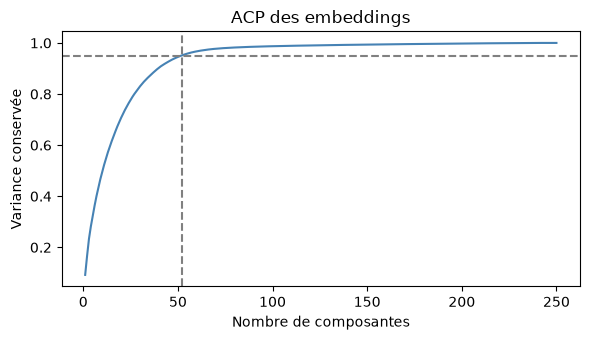

mélange ACP  1 h, alpha 0.7             validation HR@5 = 30.54% (+/- 0.33%)
ACP contre embeddings complets : 400 contre 254, p = 0.000


In [15]:
# L'ACP est apprise sur un article sur cinq : c'est 5 fois plus rapide et largement suffisant
# pour trouver les grandes directions des données. Elle est ensuite appliquée à tous les articles.
acp = PCA(random_state=GRAINE).fit(embeddings[::5])
variance_cumulee = np.cumsum(acp.explained_variance_ratio_)
N_COMPOSANTES = int(np.argmax(variance_cumulee >= 0.95) + 1)
print(f"{N_COMPOSANTES} composantes conservent {variance_cumulee[N_COMPOSANTES - 1]:.1%} de la variance (au lieu de 250)")

plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, 251), variance_cumulee, color="steelblue")
plt.axhline(0.95, color="grey", linestyle="--")
plt.axvline(N_COMPOSANTES, color="grey", linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance conservée")
plt.title("ACP des embeddings")
plt.tight_layout()
plt.show()

acp = PCA(n_components=N_COMPOSANTES, random_state=GRAINE).fit(embeddings[::5])
emb_acp = acp.transform(embeddings).astype(np.float32)
EMB_ACP = emb_acp / np.linalg.norm(emb_acp, axis=1, keepdims=True)

# Même mesure qu'en section 3.4, avec les embeddings réduits : le HR@5 doit rester le même
connus, deja_lus, a_lire, utilisateurs = VALIDATION
recos = recommander_melange(connus, deja_lus, utilisateurs, HEURES_POP, ALPHA, emb=EMB_ACP)
s_acp = noter("mélange ACP", f"{HEURES_POP} h, alpha {ALPHA}", "validation", reussites(recos, a_lire, utilisateurs))
a_seul, b_seul, p = mcnemar(s_acp, s_mel)
print(f"ACP contre embeddings complets : {a_seul} contre {b_seul}, p = {p:.3f}")

### Export

L'Azure Function a besoin de peu de choses pour recommander :
- l'historique de lecture de chaque utilisateur ;
- la liste des articles populaires du moment, avec leur score de popularité ;
- les embeddings réduits, mais seulement pour les articles déjà lus par quelqu'un ou candidats : les autres
  ne servent jamais au calcul ;
- la valeur d'alpha retenue.

Pour la popularité, on prend la fin du trafic réel (le 17 octobre) comme "maintenant" : après cette date il ne
reste que quelques clics isolés, qui donneraient une fenêtre presque vide.

Tout est rangé dans un seul fichier `.npz` (format de NumPy qui regroupe plusieurs tableaux, compressé). Ce
fichier sera déposé dans le Blob Storage Azure et lu par la Function grâce au "Blob input binding". On le
préfère à un pickle car il se relit sans exécuter de code Python, donc sans risque si le fichier était modifié.

In [16]:
fin_trafic = pd.Timestamp("2017-10-18").value // 10**6
clics_export = clics[clics.click_timestamp < fin_trafic].sort_values(["user_id", "click_timestamp"])

# Articles populaires de la dernière fenêtre, comme dans recommander_melange
pop = classement_popularite(clics_export, HEURES_POP).iloc[:300]

# Historique compact : tous les articles lus, utilisateur après utilisateur, et pour chaque utilisateur
# la position où commence sa liste (debut[i] à debut[i+1]). C'est beaucoup plus léger qu'un dictionnaire.
user_ids, debuts = np.unique(clics_export.user_id.values, return_index=True)
debuts = np.append(debuts, len(clics_export))
historique = clics_export.click_article_id.values

# Seuls les articles lus ou candidats sont exportés, triés pour pouvoir les retrouver vite
articles_utiles = np.union1d(historique, pop.index.values)

chemin = f"{DOSSIER_DONNEES}/modele_reco.npz"
np.savez_compressed(
    chemin,
    user_ids=user_ids.astype(np.int32),
    debuts=debuts.astype(np.int64),
    historique=historique.astype(np.int32),
    pop_articles=pop.index.values.astype(np.int32),
    pop_scores=(pop.values / pop.values[0]).astype(np.float32),
    article_ids=articles_utiles.astype(np.int32),
    embeddings=EMB_ACP[articles_utiles],
    alpha=np.float32(ALPHA),
)

print(f"{len(user_ids):,} utilisateurs, {len(articles_utiles):,} articles exportés")
print(f"Fichier {chemin} : {os.path.getsize(chemin) / 1e6:.1f} Mo")

322,892 utilisateurs, 45,695 articles exportés
Fichier ../data/modele_reco.npz : 15.1 Mo
